<table align="center" style="border:none; width:100%;"><tr style="border:none; background:none;">
<td style="border:none; width:150px;" align="left">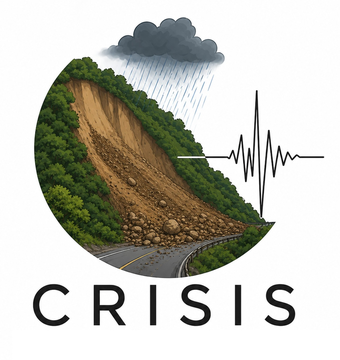</td>
<td style="border:none;" align="center"><h1 style="text-align:center; font-size:2.2em; white-space:nowrap;">CRISIS Landlab Component — Example</h1></td>
<td style="border:none; width:150px;" align="right">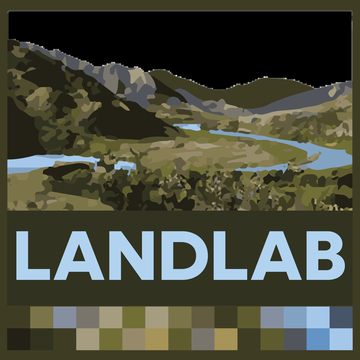</td>
</tr></table>

This notebook runs the CRISIS Landlab component on a small watershed in **Utuado, Puerto Rico**, using transient pore pressure heads estimated by [ParFlow](https://parflow.org) under **Hurricane Maria**. The input files are in the `Input Files` folder:

<table align="left" style="margin-left:0; margin-right:auto;">
<tr><th style="text-align:left;">File</th><th style="text-align:left;">What it is</th></tr>
<tr><td style="text-align:left;"><code>dem.asc</code></td><td style="text-align:left;">DEM (Esri ASCII grid, 1 m spatial resolution, rows ordered from north to south: the first row is the northern edge)</td></tr>
<tr><td style="text-align:left;"><code>Pressure_head_T{t}Z{z}.h5</code></td><td style="text-align:left;">Pore pressure head (m) from ParFlow, rows ordered from north to south, one file per time step <code>t</code> (0–72) and depth layer <code>z</code> (1–8)</td></tr>
</table>
<br clear="all">

The notebook goes step by step:

1. set the folders and model settings (section 2);
2. load the DEM onto a Landlab grid and plot it (section 3);
3. compute the **slope**, **D8 flow direction**, and **flow accumulation** with Landlab, and plot them (section 4);
4. explore the **pore pressure head** files interactively, at any time step and depth (section 5);
5. define the CRISIS parameters, the `params` dictionary (section 6);
6. run CRISIS over all time steps (section 7);
7. explore the predicted landslides interactively (section 8) and write the output files to the folder `Output Files_external hydrological model` (section 9);
8. repeat the run with a steady-state, spatially uniform pore pressure coefficient $R_u$ = 0.44 instead of the ParFlow files (section 10), with its results in the folder `Output Files Ru 0.44`.

All file paths are **relative to this notebook's folder** (`Example/`), so the notebook runs the same way on any computer. Jupyter starts in the notebook's folder automatically.

See `CRISIS_Manual.pdf` (one folder up) for a full description of the inputs, parameters, and outputs.

<div class="alert alert-block alert-success">
<b>✏️ Using your own data.</b> The inputs you enter are shown in <b>green boxes</b> like this one (sections 2, 6 and 10). Put your input files in a folder, change only the values listed in the green boxes, and run all cells (<i>Run → Run All Cells</i>). Everything else in the notebook runs as it is.
</div>

## 1. Imports

`CrisisComponent` is imported from Landlab, like any other Landlab component. If your Landlab installation does not include CRISIS yet, it is imported from the CRISIS files one folder up.

In [1]:
# standard Python tools
import sys
import warnings
from pathlib import Path

# numbers and arrays
import numpy as np

# plotting
import matplotlib.pyplot as plt

# colors and shading used in the maps
from matplotlib.colors import LightSource, ListedColormap, LogNorm, TwoSlopeNorm

# legend boxes for the flow direction map
from matplotlib.patches import Patch

# used to fill the area outside the DEM for the hillshade
from scipy.ndimage import distance_transform_edt

# sliders for the interactive plots
import ipywidgets as widgets
from ipywidgets import interact

# Landlab: read the DEM and compute flow direction / flow accumulation
from landlab.io import read_esri_ascii
from landlab.components import FlowAccumulator

# CRISIS: the component, load_h5 (reads an .h5 input file)
# and lower_left_cell_center (center of the lower-left cell, from the DEM corner)
from landlab.components import CrisisComponent
from landlab.components.crisis._crisis_core import load_h5, lower_left_cell_center

In [2]:
# default size and font of the figures:

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})

# hide warnings that shapefile column names are shortened to 10 characters
# (expected: the shapefile format allows at most 10 characters per column name)
warnings.filterwarnings("ignore", message="Column names longer than 10 characters")
warnings.filterwarnings("ignore", message="Normalized/laundered field name")

# hide warnings about deprecated or future library changes
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

## 2. Folders and model settings

The input folder and the output folder are given **relative** to this notebook. The output folder is **named automatically** after the pore pressure indicator (`Hydrological_model_indicator`): `Output Files_external hydrological model` when the pore pressure heads vary in time (`Hydrological_model_indicator` = 2, HDF5 files from an external hydrological model, or 3, a grid field written by a coupled Landlab component), and `Output Files Ru <value>` (e.g. `Output Files Ru 0.44`) for a steady-state, spatially uniform pore pressure coefficient $R_u$. CRISIS creates the folder if it does not exist.

The depth discretization must match the pore pressure files: 8 depth layers (`Z1` … `Z8`) between 0.125 m and 1.875 m, counted from the ground surface down. The number of time steps is not an input: CRISIS counts it from the files (73 here, `T0` … `T72`). Every layer is checked for failure, including the first one (`Z1`, at 0.125 m); only a layer at depth 0, the ground surface, would be skipped (see the note on `z_min` in Section 7 of `CRISIS_Manual.pdf`).

<div class="alert alert-block alert-success">
<b>✏️ Your inputs: folders and model settings</b> (code cell below)
<table>
<tr><th style="text-align:left;">Input</th><th style="text-align:left;">What to enter</th><th style="text-align:left;">This example</th></tr>
<tr><td><code>INPUT_DIR</code></td><td>folder with your DEM and pore pressure head files (relative to this notebook)</td><td><code>"Input Files"</code></td></tr>
<tr><td><code>DEM_FILE</code></td><td>your DEM: Esri ASCII grid (<code>.asc</code>), rows ordered from north to south, in a projected coordinate system (meters)</td><td><code>"dem.asc"</code></td></tr>
<tr><td><code>DEPTH_POINTS</code></td><td>number of depth layers of your pore pressure files (<code>Z1</code> … <code>Z{DEPTH_POINTS}</code>)</td><td><code>8</code></td></tr>
<tr><td><code>Z_MIN</code>, <code>Z_MAX</code></td><td>depth of the first and last layer (m)</td><td><code>0.125</code>, <code>1.875</code></td></tr>
</table>
</div>

In [3]:
# ✏️ YOUR INPUTS: edit the values in this cell (see the green box above)

# folder with the input files (relative to this notebook)
INPUT_DIR = Path("Input Files")

# output folder, named automatically after the pore pressure indicator
def output_folder(params):

    # pore pressure heads that vary in time (2 = HDF5 files from an external
    # hydrological model, 3 = grid field written by a coupled Landlab component)
    if params["Hydrological_model_indicator"] in (2, 3):
        return Path("Output Files_external hydrological model")

    # steady-state, spatially uniform pore pressure coefficient Ru
    return Path(f"Output Files Ru {params['Ru']}")

# the DEM file
DEM_FILE = INPUT_DIR / "dem.asc"

# number of depth layers (Z1 ... Z8)
DEPTH_POINTS = 8

# depth of the first and last layer (m)
Z_MIN, Z_MAX = 0.125, 1.875

# depth of every layer (m)
DEPTHS = np.linspace(Z_MIN, Z_MAX, DEPTH_POINTS)

# check that the inputs are found
print("DEM file:", DEM_FILE, "| exists:", DEM_FILE.exists())
print("Pressure head files found:", len(list(INPUT_DIR.glob("Pressure_head_T*Z*.h5"))))
print("Depth of each layer (m):", DEPTHS)

DEM file: Input Files\dem.asc | exists: True
Pressure head files found: 584
Depth of each layer (m): [0.125 0.375 0.625 0.875 1.125 1.375 1.625 1.875]


## 3. Load the DEM onto a Landlab grid

`read_esri_ascii` creates a `RasterModelGrid` from the DEM header (rows, columns, cell size, lower-left coordinates) and stores the elevations as the field `topographic__elevation`. It also flips the DEM from rows ordered north to south (the file) to Landlab's row order (row 0 = south). `read_esri_ascii` places the grid nodes on the header's `xllcorner` / `yllcorner`, the outer corner of the lower-left cell. CRISIS uses the cell centers instead (half a cell further north-east) for its shapefiles, and the maps below use the same cell centers.

Cells outside the watershed carry the no-data value given by `NODATA_value` in the DEM header (−9999 in this example). It is set below (`NODATA = -9999.0`) for the maps and the boundary conditions; CRISIS itself treats elevations below −900 (or NaN) as no-data, so use a no-data value below −900, such as the usual −9999. `set_watershed_boundary_condition` closes these cells and sets the watershed outlet.

In [4]:
# no-data value of the DEM (NODATA_value in the DEM header)
NODATA = -9999.0

# create the Landlab grid from the DEM and store the elevations on it
grid, elevation = read_esri_ascii(DEM_FILE, name="topographic__elevation")

# close the cells outside the watershed (no-data cells) and set the outlet
grid.set_watershed_boundary_condition(node_data=elevation, nodata_value=NODATA)

# grid size
nrows, ncols = grid.shape

# cell size (m)
dx = grid.dx

# True inside the DEM boundary, False outside
inside = ~np.isclose(elevation, NODATA).reshape(grid.shape)

# summary of the grid
print(f"Grid: {nrows} rows x {ncols} columns, cell size = {dx} m")
print(f"Cells inside the watershed: {inside.sum()} of {inside.size}")
print(f"Elevation: {elevation[inside.ravel()].min():.1f} to {elevation[inside.ravel()].max():.1f} m")

Grid: 154 rows x 119 columns, cell size = 1.0 m
Cells inside the watershed: 10312 of 18326
Elevation: 479.8 to 577.6 m


### Plotting helpers

Every map below is drawn in real-world coordinates (the cell centers computed from the DEM header, as in the shapefiles written by CRISIS), with **north at the top**, and masked outside the DEM boundary. A hillshade of the DEM is drawn underneath for context.

In [5]:
# x and y coordinates of every cell center (m), from the DEM header, like the shapefiles
# written by CRISIS (read_esri_ascii places the grid nodes on the header's xllcorner /
# yllcorner, the outer corner of the lower-left cell, half a cell from its center)
corner = {"xllcorner": grid.x_of_node.min(), "yllcorner": grid.y_of_node.min(), "cellsize": dx}
x0, y0 = lower_left_cell_center(corner)
x = (x0 + grid.x_of_node - grid.x_of_node.min()).reshape(grid.shape)
y = (y0 + grid.y_of_node - grid.y_of_node.min()).reshape(grid.shape)

# map limits, so the maps are drawn in real-world coordinates
extent = [x.min() - dx / 2, x.max() + dx / 2, y.min() - dx / 2, y.max() + dx / 2]

# elevation as a 2D map
z = elevation.reshape(grid.shape).astype(float)

# outside the DEM, copy the nearest inside elevation (avoids a dark rim in the hillshade)
nearest = distance_transform_edt(~inside, return_distances=False, return_indices=True)
z_filled = z[tuple(nearest)]

# hillshade of the DEM (LightSource expects row 0 at the top, so flip, shade, flip back)
hillshade = np.flipud(LightSource(azdeg=315, altdeg=45).hillshade(np.flipud(z_filled), dx=dx, dy=dx))

# hide the hillshade outside the DEM
hillshade = np.ma.masked_where(~inside, hillshade)


# turn grid values into a 2D map, hidden outside the DEM
def masked(values):
    return np.ma.masked_where(~inside, np.asarray(values, dtype=float).reshape(grid.shape))


# draw the hillshade background, title and axis labels
def map_axes(ax, title):

    # hillshade in gray, north at the top
    ax.imshow(hillshade, origin="lower", extent=extent, cmap="gray", interpolation="nearest")

    # title and axis labels
    ax.set_title(title)
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")

    # show full coordinates on the axes
    ax.ticklabel_format(useOffset=False, style="plain")
    ax.tick_params(axis="x", labelrotation=30)


# draw a map of grid values on top of the hillshade, with a color bar
def show_map(values, title, label, ax=None, alpha=0.75, **kwargs):

    # create a new figure if none is given
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 7))

    # background
    map_axes(ax, title)

    # the values, semi-transparent over the hillshade
    im = ax.imshow(masked(values), origin="lower", extent=extent, interpolation="nearest",
                   alpha=alpha, **kwargs)

    # color bar
    plt.colorbar(im, ax=ax, label=label, shrink=0.8)
    return ax

### DEM

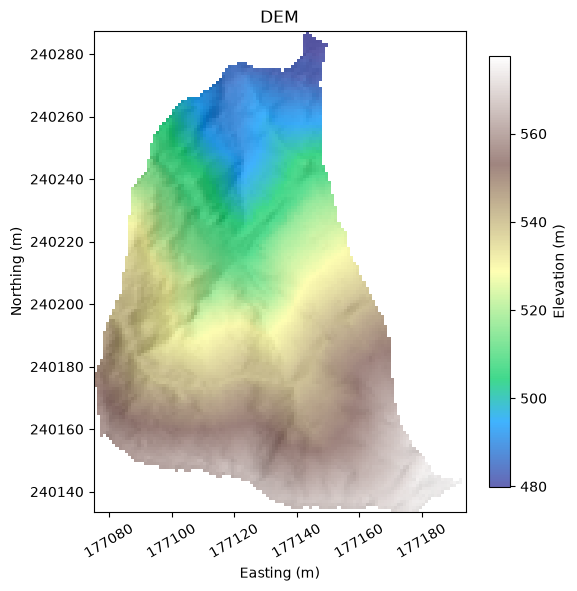

In [6]:
# map of the elevation
show_map(elevation, "DEM", "Elevation (m)", cmap="terrain")
plt.show()

## 4. Slope, flow direction, and flow accumulation (Landlab)

CRISIS does not compute topographic fields itself; they are computed here with Landlab and stored on the grid, where the component reads them:

<table align="left" style="margin-left:0; margin-right:auto;">
<tr><th style="text-align:left;">Grid field</th><th style="text-align:left;">Computed by</th><th style="text-align:left;">Used by CRISIS for</th></tr>
<tr><td style="text-align:left;"><code>topographic__slope</code> (degrees)</td><td style="text-align:left;"><code>grid.calc_slope_at_node</code></td><td style="text-align:left;">factor of safety and Newmark displacement</td></tr>
<tr><td style="text-align:left;"><code>flow__receiver_node</code> (D8)</td><td style="text-align:left;"><code>FlowAccumulator</code> with <code>FlowDirectorD8</code></td><td style="text-align:left;">growing each landslide upslope</td></tr>
<tr><td style="text-align:left;"><code>drainage_area</code> (m²)</td><td style="text-align:left;"><code>FlowAccumulator</code></td><td style="text-align:left;">the order in which triggering cells are processed, and the upslope search (a cell joins a landslide only if its contributing area is no larger than that of the cell it drains into)</td></tr>
</table>
<br clear="all">

In [7]:
# D8 flow direction and drainage area (stored on the grid)
fa = FlowAccumulator(grid, flow_director="FlowDirectorD8")
fa.run_one_step()

# slope in degrees (stored on the grid)
slope = grid.add_zeros("topographic__slope", at="node")
slope[:] = np.degrees(grid.calc_slope_at_node("topographic__elevation"))

# list the fields now on the grid
print("Fields on the grid:", sorted(grid.at_node.keys()))

Fields on the grid: ['drainage_area', 'flow__data_structure_delta', 'flow__link_to_receiver_node', 'flow__receiver_node', 'flow__sink_flag', 'flow__upstream_node_order', 'surface_water__discharge', 'topographic__elevation', 'topographic__slope', 'topographic__steepest_slope', 'water__unit_flux_in']


### Slope

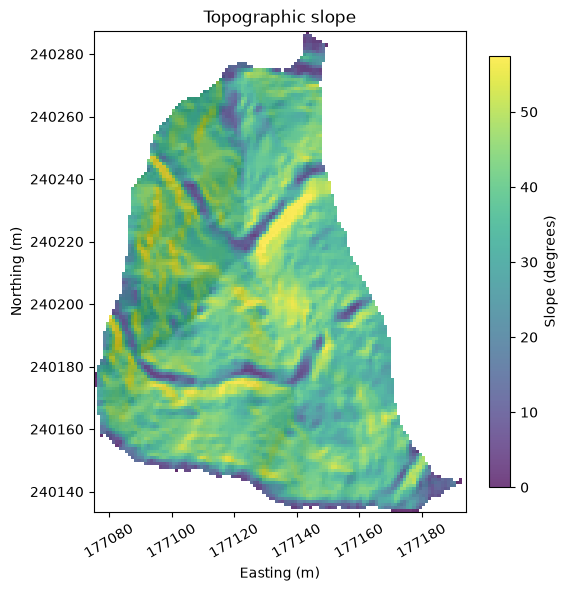

In [8]:
# map of the slope (color scale up to the 99th percentile)
show_map(slope, "Topographic slope", "Slope (degrees)", cmap="viridis", vmin=0,
         vmax=np.percentile(slope[inside.ravel()], 99))
plt.show()

### D8 flow direction

Each cell drains to one of its 8 neighbors, the one in the steepest downhill direction. The map colors every cell by its flow direction. Cells marked *outlet / pit* have no downhill neighbor.

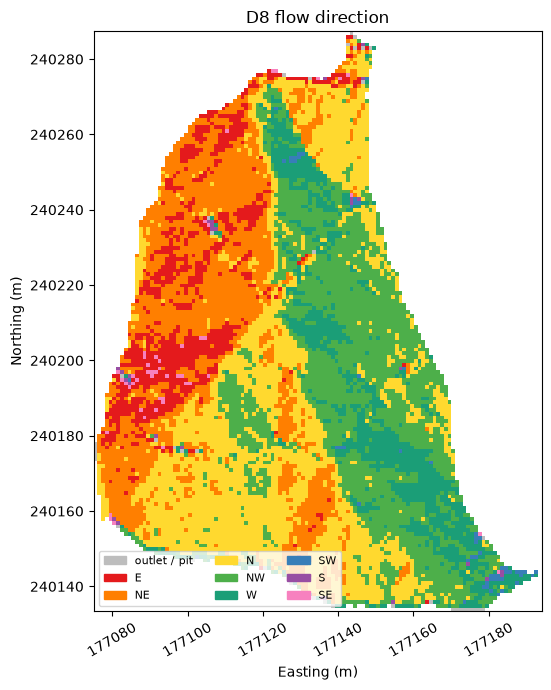

In [9]:
# the cell each cell drains to
receiver = grid.at_node["flow__receiver_node"]

# row and column of every cell
node_row, node_col = np.divmod(np.arange(grid.number_of_nodes), ncols)

# step to the receiver: +1 row = one cell north, +1 column = one cell east
d_row = node_row[receiver] - node_row
d_col = node_col[receiver] - node_col

# the 8 directions and their (row, column) steps
directions = {"E": (0, 1), "NE": (1, 1), "N": (1, 0), "NW": (1, -1),
              "W": (0, -1), "SW": (-1, -1), "S": (-1, 0), "SE": (-1, 1)}

# give each cell a number for its direction (0 = outlet / pit)
direction_code = np.zeros(grid.number_of_nodes)
for code_value, (dr, dc) in enumerate(directions.values(), start=1):
    direction_code[(d_row == dr) & (d_col == dc)] = code_value

# one color per direction (gray = outlet / pit)
colors = ["#bdbdbd", "#e41a1c", "#ff7f00", "#ffd92f", "#4daf4a",
          "#1b9e77", "#377eb8", "#984ea3", "#f781bf"]

# one map
fig, ax1 = plt.subplots(figsize=(6.5, 7))

# cells colored by flow direction
map_axes(ax1, "D8 flow direction")
ax1.imshow(masked(direction_code), origin="lower", extent=extent, interpolation="nearest",
           cmap=ListedColormap(colors), vmin=-0.5, vmax=8.5)

# legend of the colors
handles = [Patch(color=colors[0], label="outlet / pit")] + \
          [Patch(color=colors[i], label=name) for i, name in enumerate(directions, start=1)]
ax1.legend(handles=handles, loc="lower left", fontsize=8, ncol=3)

plt.tight_layout()
plt.show()

### Flow accumulation

Flow accumulation is the number of cells that drain through each cell, including the cell itself (drainage area ÷ cell area). It is shown on a logarithmic scale: the channel network stands out as the cells with large values.

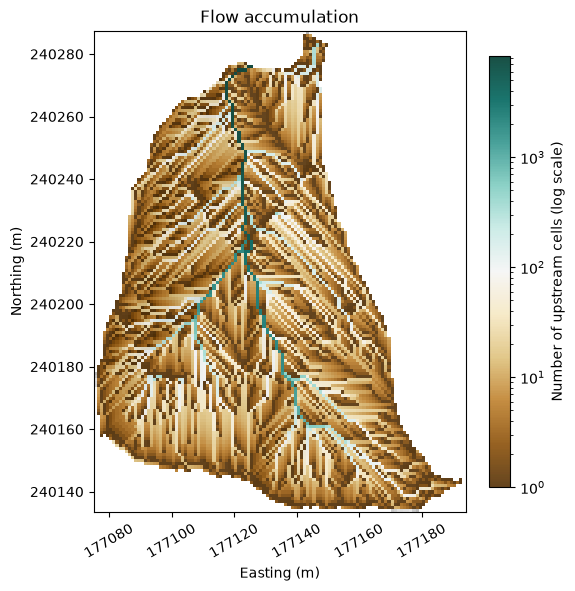

In [10]:
# number of cells draining through each cell (drainage area / cell area)
flow_accumulation = grid.at_node["drainage_area"] / dx**2

# map on a log scale
show_map(flow_accumulation, "Flow accumulation", "Number of upstream cells (log scale)",
         cmap="BrBG", alpha=0.9, norm=LogNorm(vmin=1, vmax=flow_accumulation[inside.ravel()].max()))
plt.show()

## 5. Pore pressure head (input files)

The pore pressure head files come from an external hydrological model, one file per time step `T` and depth layer `Z`, named `Pressure_head_T{t}Z{z}.h5`. Like the DEM, they store their **rows from north to south**; `load_h5` flips them to Landlab's orientation, so they line up with the grid.

The pore pressure heads can be given in three ways (`Hydrological_model_indicator`; see Sections 6 and 7 of `CRISIS_Manual.pdf`):

- **1, constant $R_u$:** a steady-state, spatially uniform pore pressure coefficient, which needs no pore pressure files (section 10).
- **2, external hydrological model (used in this example):** the hydrological model (here ParFlow) is run on its own, outside Landlab, for all time steps, before CRISIS. Its results are saved as these files, and CRISIS reads the files of each time step in turn.
- **3, coupled Landlab component:** a hydrological Landlab component runs together with CRISIS, in the same Landlab time loop. At every time step it writes the pore pressure heads to the node field `soil_water__pressure_head` (shape `(number_of_nodes, Depth_points)`), and CRISIS reads them for that time step. No files are needed; a grid field is already in Landlab's row order, so it is not flipped.

Positive pore pressure heads (dark blue) mean water pressure above atmospheric (saturated soil); negative values (light blue) mean suction (unsaturated soil). The map is masked by the DEM boundary.

First a static map at one time step and depth:

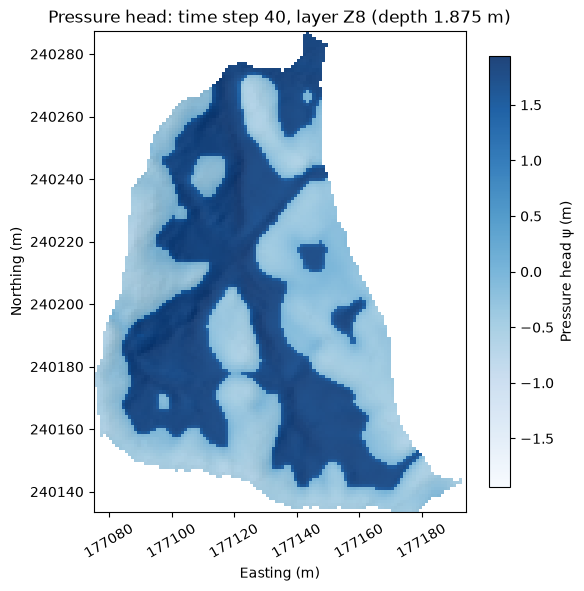

ψ inside the watershed: min = -0.704 m, max = 1.939 m, saturated cells (ψ > 0): 47.1 %


In [11]:
# map of the pressure head at time step t and depth layer z
def plot_pressure_head(t=40, z=8):

    # read the file (load_h5 also flips it to Landlab's orientation)
    psi = load_h5(INPUT_DIR / f"Pressure_head_T{t}Z{z}.h5")

    # values inside the watershed only
    psi_inside = psi[inside]

    # symmetric color range, so 0 is in the middle of the color bar
    limit = max(abs(psi_inside.min()), abs(psi_inside.max()), 1e-6)

    # draw the map (light blue = suction, dark blue = positive pressure)
    fig, ax = plt.subplots(figsize=(6, 7))
    show_map(psi, f"Pressure head: time step {t}, layer Z{z} (depth {DEPTHS[z - 1]:.3f} m)",
             "Pressure head ψ (m)", ax=ax, alpha=0.9, cmap="Blues",
             norm=TwoSlopeNorm(vmin=-limit, vcenter=0.0, vmax=limit))
    plt.show()

    # short summary of the values
    print(f"ψ inside the watershed: min = {psi_inside.min():.3f} m, max = {psi_inside.max():.3f} m, "
          f"saturated cells (ψ > 0): {(psi_inside > 0).mean() * 100:.1f} %")


# time step 40, deepest layer
plot_pressure_head(t=40, z=8)

**Interactive:** move the sliders to see any time step and depth layer.

In [12]:
# number of time steps of the files (one Z1 file per time step)
N_STEPS = len(list(INPUT_DIR.glob("Pressure_head_T*Z1.h5")))

# sliders to choose the time step and the depth layer
interact(plot_pressure_head,
         t=widgets.IntSlider(value=40, min=0, max=N_STEPS - 1, description="time step"),
         z=widgets.IntSlider(value=8, min=1, max=DEPTH_POINTS, description="depth layer"));

interactive(children=(IntSlider(value=40, description='time step', max=72), IntSlider(value=8, description='de…

## 6. Parameters (the `params` dictionary)

All CRISIS parameters are given in the `params` dictionary below; every key is described in Section 7 of `CRISIS_Manual.pdf`. This example uses:

- **rainfall only** (`Triggering_Indicator = 1`);
- **pore pressure heads from files** (`Hydrological_model_indicator = 2`);
- **full saturation** for the effective stress (`Strength_variation_with_theta = 1`, so no water content files);
- **uniform shear strength** (`Strength_indicator = 1`): c′ = 20 kPa, φ′ = 37°.

<div class="alert alert-block alert-success">
<b>✏️ Your inputs: model parameters</b> (in the <code>params</code> dictionary below; all keys are described in Section 7 of <code>CRISIS_Manual.pdf</code>)
<table>
<tr><th style="text-align:left;">Key</th><th style="text-align:left;">What to enter</th><th style="text-align:left;">This example</th></tr>
<tr><td><code>Coordinate_Reference_System</code></td><td>EPSG code of the projected coordinate system of your DEM</td><td><code>"EPSG:6566"</code></td></tr>
<tr><td><code>Triggering_Indicator</code></td><td>1 = rainfall only, 2 = rainfall + earthquake (this also needs the earthquake keys, Section 7 of <code>CRISIS_Manual.pdf</code>)</td><td><code>1</code></td></tr>
<tr><td><code>Gamma</code></td><td>soil unit weight (kN/m³)</td><td><code>22.0</code></td></tr>
<tr><td><code>Min_LD_area</code></td><td>smallest landslide kept (m²)</td><td><code>12.0</code></td></tr>
<tr><td><code>top_or_bottom_indicator</code></td><td>1 = shallowest, 2 = deepest failing depth starts the landslide</td><td><code>1</code></td></tr>
<tr><td><code>Hydrological_model_indicator</code></td><td>1 = constant <code>Ru</code>, 2 = pore pressure head files (folder in <code>hydro_files_dir</code>), 3 = grid field <code>soil_water__pressure_head</code> written by a coupled Landlab component</td><td><code>2</code></td></tr>
<tr><td><code>Strength_variation_with_theta</code></td><td>1 = fully saturated, 2 = water content files (<code>theta_files_dir</code>, with <code>Theta_s</code>, <code>Theta_r</code>), 3 = grid field <code>soil_water__volume_fraction</code> written by a coupled Landlab component; ignored (fully saturated) when <code>Hydrological_model_indicator</code> = 1</td><td><code>1</code></td></tr>
<tr><td><code>Strength_indicator</code></td><td>1 = uniform strength (<code>c</code> in kPa, <code>Phi</code> in degrees), 2 = 3D strength files</td><td><code>1</code>: <code>c</code> = 20, <code>Phi</code> = 37</td></tr>
</table>
The output folder (<code>output_dir</code>) is named automatically after the pore pressure indicator (section 2). The other keys (<code>dem_file</code>, <code>hydro_files_dir</code>, <code>z_min</code>, <code>z_max</code>, <code>Depth_points</code>) are filled in automatically from section 2: do not change them here. CRISIS reads the cell size automatically from the header of <code>dem_file</code>.
</div>

In [13]:
# ✏️ YOUR INPUTS: edit the values in this cell (see the green box above)

params = {

    # ── Coordinate system ──────────────────────────────────────────────────
    # projected coordinate system of the DEM (used for the shapefiles)
    "Coordinate_Reference_System": "EPSG:6566",

    # ── DEM and grid ───────────────────────────────────────────────────────
    # DEM file (its header gives the cell coordinates and the cell size)
    "dem_file": str(DEM_FILE),

    # ── Triggering event ───────────────────────────────────────────────────
    # 1 = rainfall only, 2 = rainfall + earthquake
    "Triggering_Indicator": 1,

    # ── Soil column ────────────────────────────────────────────────────────
    # soil unit weight (kN/m³)
    "Gamma": 22.0,

    # depth of the first layer (m)
    "z_min": Z_MIN,

    # depth of the last layer (m)
    "z_max": Z_MAX,

    # number of depth layers
    "Depth_points": DEPTH_POINTS,

    # smallest landslide kept (m²)
    "Min_LD_area": 12.0,

    # 1 = the shallowest failing depth starts the landslide (2 = the deepest)
    "top_or_bottom_indicator": 1,

    # ── Pore pressure ──────────────────────────────────────────────────────
    # 1 = constant Ru, 2 = pore pressure head files (HDF5, external hydrological model),
    # 3 = grid field soil_water__pressure_head written by a coupled Landlab component
    "Hydrological_model_indicator": 2,

    # folder with the Pressure_head_T{t}Z{z}.h5 files
    "hydro_files_dir": str(INPUT_DIR),

    # used only when Hydrological_model_indicator = 1
    "Ru": None,

    # ── Effective stress (water content) ───────────────────────────────────
    # 1 = fully saturated (chi = 1), so no water content files;
    # 2 = water content files Theta_T{t}Z{z}.h5 (folder in theta_files_dir);
    # 3 = grid field soil_water__volume_fraction written by a coupled Landlab component
    "Strength_variation_with_theta": 1,
    "theta_files_dir": "",

    # saturated and residual water content
    "Theta_s": 0.45,
    "Theta_r": 0.10,

    # ── Shear strength ─────────────────────────────────────────────────────
    # 1 = the same strength everywhere (2 = 3D strength files)
    "Strength_indicator": 1,

    # effective cohesion (kPa)
    "c": 20.0,

    # effective friction angle (degrees)
    "Phi": 37.0,
}

# output folder, named after the pore pressure indicator ("Output Files_external hydrological model")
OUTPUT_DIR = output_folder(params)
params["output_dir"] = str(OUTPUT_DIR)

## 7. Run CRISIS

The component is created with the grid and `params`, and `run_one_step()` is called once per time step. After each step, the fields `failure__depth`, `triggering__cells` and `landslide__failure_id` describe the landslides that are **new** in that step (the `*_accumulated` fields hold all landslides so far); copies are kept here so they can be explored afterwards.

In [14]:
# create the CRISIS component
crisis = CrisisComponent(grid, params)

# copies of the results of every time step, for the plots below
history = {"failure__depth": [], "triggering__cells": []}

# loop over the time steps (CRISIS counts them from the files)
for t in range(crisis.number_of_time_steps):

    # run CRISIS for this time step
    crisis.run_one_step()

    # keep a copy of this step's results
    for name in history:
        history[name].append(grid.at_node[name].copy())

    # print the number of new landslides, if any
    n_new = int(crisis.state["Total_Current_NL_vector_with_time"][t])
    if n_new:
        print(f"time step {t:2d}: {n_new} new landslide(s)")

# all results accumulated by CRISIS
state = crisis.state

# totals at the end of the run
print()
print("Total landslides:", int(state["Total_Cumulative_NL_vector_with_time"][-1]))
print(f"Total landslide area:   {state['Total_Cumulative_Area_vector_with_time'][-1]:.1f} m²")
print(f"Total landslide volume: {state['Total_Cumulative_Volume_vector_with_time'][-1]:.1f} m³")

Hydrological_model_indicator = 2: 73 time step(s) found in the HDF5 files (T0 ... T72).
time step 28: 2 new landslide(s)
time step 29: 1 new landslide(s)
time step 30: 1 new landslide(s)
time step 32: 1 new landslide(s)
time step 33: 1 new landslide(s)
time step 34: 2 new landslide(s)
time step 35: 1 new landslide(s)
time step 36: 3 new landslide(s)
time step 37: 4 new landslide(s)
time step 38: 2 new landslide(s)
time step 39: 1 new landslide(s)
time step 40: 2 new landslide(s)
time step 41: 2 new landslide(s)
time step 42: 4 new landslide(s)
time step 43: 3 new landslide(s)
time step 44: 1 new landslide(s)
time step 45: 2 new landslide(s)
time step 46: 6 new landslide(s)
time step 48: 2 new landslide(s)
time step 49: 1 new landslide(s)

Total landslides: 42
Total landslide area:   1065.0 m²
Total landslide volume: 1582.7 m³


## 8. Results

### Landslide area density over time

The landslide area density is the total area of all landslides up to each time step (cumulative), divided by the study area (the cells inside the DEM boundary only).

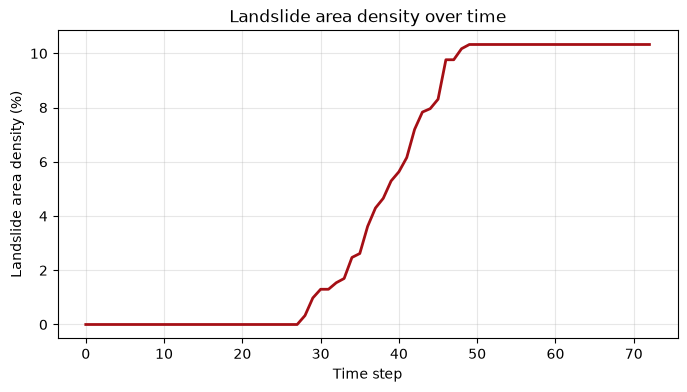

Study area: 10312 m²
Landslide area density at the end of the run: 10.33 %


In [15]:
# study area: cells inside the DEM boundary only (m²)
study_area = inside.sum() * dx**2

# time step numbers
steps = np.arange(crisis.number_of_time_steps)

# landslide area density (%) = cumulative landslide area / study area
area_density = state["Total_Cumulative_Area_vector_with_time"] / study_area * 100

# plot it over time
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(steps, area_density, color="#a50f15", lw=2)
ax.set_xlabel("Time step")
ax.set_ylabel("Landslide area density (%)")
ax.set_title("Landslide area density over time")
ax.grid(alpha=0.3)
plt.show()

# final value
print(f"Study area: {study_area:.0f} m²")
print(f"Landslide area density at the end of the run: {area_density[-1]:.2f} %")

### Frequency distribution of landslide areas and volumes

Number of landslides in each size class, for all landslides predicted during the run. The size classes are spaced evenly on a logarithmic scale.

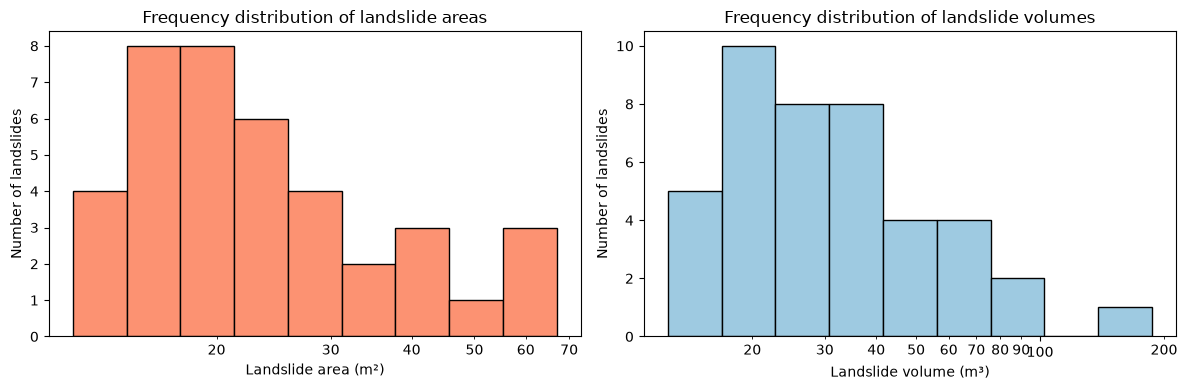

Number of landslides: 42
Area:   12 to 67 m²
Volume: 12.5 to 186.9 m³


In [16]:
# area (m²) and volume (m³) of every landslide predicted during the run
areas = np.asarray(state["Individual_Cumulative_areas"], dtype=float)
volumes = np.asarray(state["Individual_Cumulative_volumes"], dtype=float)

# two plots side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for ax, values, color, label in ((ax1, areas, "#fc9272", "Landslide area (m²)"),
                                 (ax2, volumes, "#9ecae1", "Landslide volume (m³)")):

    # size classes, evenly spaced on a log scale
    bins = np.logspace(np.log10(values.min()), np.log10(values.max()), 10)

    # histogram: number of landslides in each class
    ax.hist(values, bins=bins, color=color, edgecolor="k")
    ax.set_xscale("log")

    # show plain numbers on the log axis (20, 30, ... instead of 2×10¹)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.set_xlabel(label)
    ax.set_ylabel("Number of landslides")
    ax.set_title("Frequency distribution of " + label.split(" (")[0].lower() + "s")
plt.tight_layout()
plt.show()

# summary
print(f"Number of landslides: {len(areas)}")
print(f"Area:   {areas.min():.0f} to {areas.max():.0f} m²")
print(f"Volume: {volumes.min():.1f} to {volumes.max():.1f} m³")

### Volume–area relation

Volume against area of every landslide, on log–log axes, with a power-law fit $V = \alpha\, A^{\gamma}$. The fit is a straight line through $\log_{10} V$ against $\log_{10} A$ (least squares).

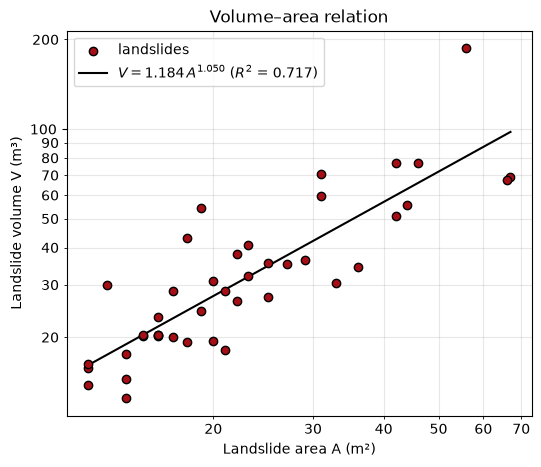

Power-law fit: V = 1.1839 * A^1.0499   (R² = 0.717, 42 landslides)


In [17]:
# straight-line fit of log10(V) against log10(A): slope = gamma, intercept = log10(alpha)
gamma, log_alpha = np.polyfit(np.log10(areas), np.log10(volumes), 1)
alpha = 10**log_alpha

# goodness of fit (R², in log space)
predicted = log_alpha + gamma * np.log10(areas)
r2 = 1 - np.sum((np.log10(volumes) - predicted)**2) / np.sum((np.log10(volumes) - np.log10(volumes).mean())**2)

# landslides as points
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(areas, volumes, color="#a50f15", edgecolor="k", zorder=3, label="landslides")

# power-law fit as a line
A_line = np.logspace(np.log10(areas.min()), np.log10(areas.max()), 50)
ax.plot(A_line, alpha * A_line**gamma, color="k", lw=1.5,
        label=f"$V = {alpha:.3f}\\,A^{{{gamma:.3f}}}$ ($R^2$ = {r2:.3f})")

# log-log axes, labels and legend
ax.set_xscale("log")
ax.set_yscale("log")

# show plain numbers on the log axes (20, 30, ... instead of 2×10¹)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.xaxis.set_minor_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("Landslide area A (m²)")
ax.set_ylabel("Landslide volume V (m³)")
ax.set_title("Volume–area relation")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.show()

# fitted parameters
print(f"Power-law fit: V = {alpha:.4f} * A^{gamma:.4f}   (R² = {r2:.3f}, {len(areas)} landslides)")

### Landslide map at any time step (interactive)

All landslides formed up to the selected time step are colored by their failure depth. The landslides that are new in that step are outlined in black, and their triggering cells are marked with a black **+**.

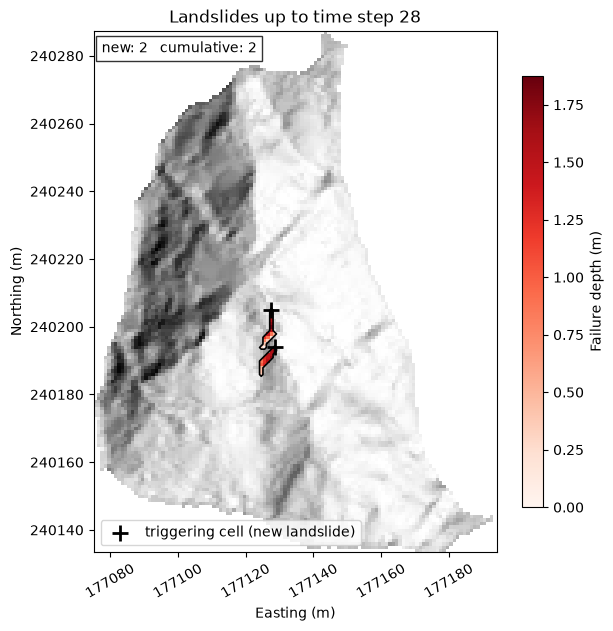

In [18]:
# map of the landslides at time step t
def plot_landslides(t=crisis.number_of_time_steps - 1):

    # background
    fig, ax = plt.subplots(figsize=(6.5, 7))
    map_axes(ax, f"Landslides up to time step {t}")

    # failure depth of every landslide formed up to this step
    # (CRISIS gives the depth of each step's new landslides; a cell fails only once, so the maximum combines them)
    depth_all = np.max(np.array(history["failure__depth"][:t + 1]), axis=0).reshape(grid.shape)

    # cells of the landslides that are new in this step
    new_cells = history["failure__depth"][t].reshape(grid.shape) > 0

    # all landslides so far, colored by failure depth
    # (the color bar is always drawn, so the map keeps the same size at every time step)
    im = ax.imshow(np.ma.masked_where(depth_all <= 0, depth_all), origin="lower", extent=extent,
                   cmap="Reds", vmin=0, vmax=Z_MAX, interpolation="nearest")
    plt.colorbar(im, ax=ax, label="Failure depth (m)", shrink=0.8)

    if new_cells.any():

        # black outline around the landslides that are new in this step
        ax.contour(x, y, new_cells.astype(float), levels=[0.5], colors="k", linewidths=1.2)

        # their triggering cells, as black +
        trig = history["triggering__cells"][t]
        ax.scatter(x.ravel()[trig], y.ravel()[trig], marker="+", s=120, c="k",
                   linewidths=2, label="triggering cell (new landslide)")
        ax.legend(loc="lower left")

    # number of new and cumulative landslides, in the corner
    n_new = int(state["Total_Current_NL_vector_with_time"][t])
    n_all = int(state["Total_Cumulative_NL_vector_with_time"][t])
    ax.text(0.02, 0.98, f"new: {n_new}   cumulative: {n_all}", transform=ax.transAxes,
            va="top", fontsize=10, bbox=dict(facecolor="white", alpha=0.8))

    # keep the same map limits at every time step
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    plt.show()


# first time step with landslides
first_with_landslides = int(np.argmax(state["Total_Current_NL_vector_with_time"] > 0))
plot_landslides(first_with_landslides)

In [19]:
# slider to choose the time step
interact(plot_landslides,
         t=widgets.IntSlider(value=first_with_landslides, min=0, max=crisis.number_of_time_steps - 1,
                             description="time step"));

interactive(children=(IntSlider(value=28, description='time step', max=72), Output()), _dom_classes=('widget-i…

### All predicted landslides

Every landslide predicted during the simulation, colored by landslide ID (from the cumulative grid field `landslide__failure_id_accumulated`).

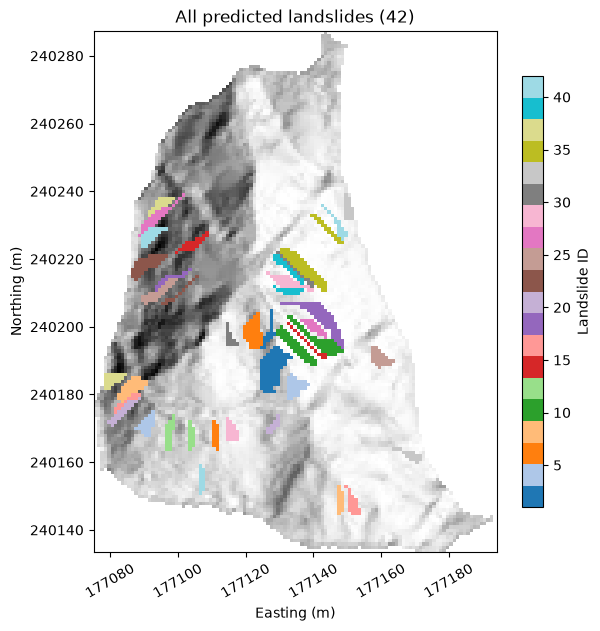

In [20]:
# landslide ID of every failed cell (NaN = no landslide)
fid = grid.at_node["landslide__failure_id_accumulated"]

# number of landslides
n_landslides = int(np.nanmax(fid)) if np.isfinite(fid).any() else 0

# map of all landslides, one color per ID
fig, ax = plt.subplots(figsize=(6.5, 7))
map_axes(ax, f"All predicted landslides ({n_landslides})")
im = ax.imshow(np.ma.masked_invalid(masked(fid)), origin="lower", extent=extent,
               cmap="tab20", interpolation="nearest")
plt.colorbar(im, ax=ax, label="Landslide ID", shrink=0.8)
plt.show()

## 9. Output files

One shapefile per time step (`Predicted_landslides_time_{t}.shp`, with all landslides formed so far) was written automatically during the run, starting at the first time step with a landslide. `write_outputs()` writes the two Excel workbooks, `Individual_landslides_with_time.xlsx` and `Total_landslides_with_time.xlsx`. All files are in `Output Files_external hydrological model`.

In [21]:
# write the two Excel workbooks
crisis.write_outputs()

# folder with the results
results_dir = OUTPUT_DIR

# Excel workbooks in the folder
excel_files = sorted(p.name for p in results_dir.glob("*.xlsx"))

# shapefiles in the folder, sorted by time step
shapefiles = sorted(results_dir.glob("Predicted_landslides_time_*.shp"),
                    key=lambda p: int(p.stem.rsplit("_", 1)[-1]))

# list what was saved
print("Output folder:", results_dir)
print("Excel workbooks:", excel_files)
print(f"Shapefiles: {len(shapefiles)}" + (f" ({shapefiles[0].name} ... {shapefiles[-1].name})" if shapefiles else ""))

Output folder: Output Files_external hydrological model
Excel workbooks: ['Individual_landslides_with_time.xlsx', 'Total_landslides_with_time.xlsx']
Shapefiles: 45 (Predicted_landslides_time_28.shp ... Predicted_landslides_time_72.shp)


### Check: shapefile of the last time step on the map

The polygons of the last shapefile are drawn on the hillshade in real-world coordinates. They should sit exactly on the landslides of the map above.

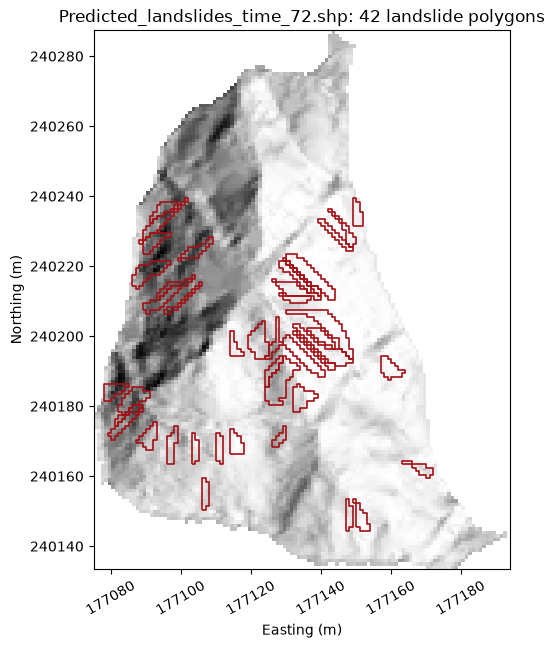

In [22]:
# library to read shapefiles
import geopandas as gpd

# read the shapefile of the last time step
gdf = gpd.read_file(shapefiles[-1])

# draw the landslide outlines on the hillshade
fig, ax = plt.subplots(figsize=(6.5, 7))
map_axes(ax, f"{shapefiles[-1].name}: {len(gdf)} landslide polygons")
gdf.boundary.plot(ax=ax, color="#a50f15", linewidth=1.2)

# same map limits as the other maps
ax.set_xlim(extent[0], extent[1])
ax.set_ylim(extent[2], extent[3])
plt.show()

## 10. Same run with a steady-state, spatially uniform pore pressure coefficient ($R_u$ = 0.44)

Instead of the ParFlow pore pressure head files, the pore pressure is given by a constant pore pressure coefficient $R_u$ (`Hydrological_model_indicator = 1`): the same at every cell and constant in time (steady state). All other inputs and parameters are the same as above.

With $\gamma$ = 22 kN/m³, $R_u$ can be at most $\gamma_w/\gamma$ = 0.446 (Section 6 of `CRISIS_Manual.pdf`), so $R_u$ = 0.44 is a valid value, just below that limit. With $R_u$, CRISIS writes steady-state outputs with no time steps: a single shapefile (`Predicted_landslides.shp`), `Individual_landslides.xlsx`, and `Total_landslides.xlsx` with a single row. CRISIS runs it as a single time step automatically.

The results of this run are saved in their own folder, named automatically `Output Files Ru 0.44`, so the files of the first run are kept.

<div class="alert alert-block alert-success">
<b>✏️ Your inputs: pore pressure coefficient</b> (code cell below)
<ul>
<li><code>params_ru["Ru"]</code>: the pore pressure coefficient, between 0 (no pore pressure) and γ<sub>w</sub>/γ (water table at the ground surface; 0.446 for γ = 22 kN/m³). This example: <code>0.44</code>.</li>
</ul>
</div>

In [23]:
# ✏️ YOUR INPUT: params_ru["Ru"] below (see the green box above)

# same DEM on a new Landlab grid (the results of the first run stay on `grid`)
grid_ru, elevation_ru = read_esri_ascii(DEM_FILE, name="topographic__elevation")

# same boundary conditions as before
grid_ru.set_watershed_boundary_condition(node_data=elevation_ru, nodata_value=NODATA)

# same D8 flow direction and drainage area
FlowAccumulator(grid_ru, flow_director="FlowDirectorD8").run_one_step()

# same slope (degrees)
slope_ru = grid_ru.add_zeros("topographic__slope", at="node")
slope_ru[:] = np.degrees(grid_ru.calc_slope_at_node("topographic__elevation"))

# same parameters as before
params_ru = dict(params)

# constant pore pressure coefficient instead of the pressure head files
params_ru["Hydrological_model_indicator"] = 1
params_ru["Ru"] = 0.44

# output folder, named after the pore pressure indicator ("Output Files Ru 0.44")
OUTPUT_DIR_RU = output_folder(params_ru)
params_ru["output_dir"] = str(OUTPUT_DIR_RU)

# create the CRISIS component for this run
crisis_ru = CrisisComponent(grid_ru, params_ru)

# copies of the results of every time step
history_ru = {"failure__depth": [], "triggering__cells": []}

# loop over the time steps
for t in range(crisis_ru.number_of_time_steps):   # a single time step with a constant Ru

    # run CRISIS for this time step
    crisis_ru.run_one_step()

    # keep a copy of this step's results
    for name in history_ru:
        history_ru[name].append(grid_ru.at_node[name].copy())

    # print the number of new landslides, if any
    n_new = int(crisis_ru.state["Total_Current_NL_vector_with_time"][t])
    if n_new:
        print(f"time step {t:2d}: {n_new} new landslide(s)")

# all results of this run
state_ru = crisis_ru.state

# write the two Excel workbooks
crisis_ru.write_outputs()

# totals at the end of the run
print()
print("Total landslides:", int(state_ru["Total_Cumulative_NL_vector_with_time"][-1]))
print(f"Total landslide area:   {state_ru['Total_Cumulative_Area_vector_with_time'][-1]:.1f} m²")
print(f"Total landslide volume: {state_ru['Total_Cumulative_Volume_vector_with_time'][-1]:.1f} m³")
print("Results saved in:", OUTPUT_DIR_RU)

time step  0: 53 new landslide(s)

Total landslides: 53
Total landslide area:   1292.0 m²
Total landslide volume: 1923.9 m³
Results saved in: Output Files Ru 0.44


### Landslide area density: both runs

The run with pore pressure heads from the external hydrological model changes over time; the steady-state $R_u$ run has a single time step, shown as a horizontal line.

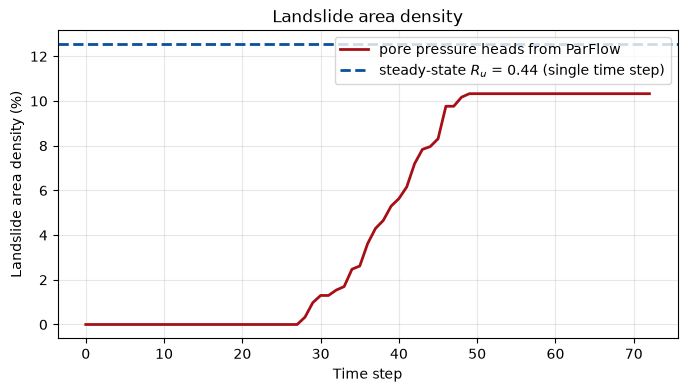

Pore pressure heads from ParFlow: 10.33 %
Steady-state R_u = 0.44:          12.53 %


In [24]:
# landslide area density (%) of the R_u run (a single time step)
area_density_ru = state_ru["Total_Cumulative_Area_vector_with_time"][-1] / study_area * 100

# both runs on one plot
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(steps, area_density, color="#a50f15", lw=2, label="pore pressure heads from ParFlow")

# the steady-state R_u run as a horizontal line
ax.axhline(area_density_ru, color="#08519c", lw=2, ls="--", label="steady-state $R_u$ = 0.44 (single time step)")
ax.set_xlabel("Time step")
ax.set_ylabel("Landslide area density (%)")
ax.set_title("Landslide area density")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

# final values
print(f"Pore pressure heads from ParFlow: {area_density[-1]:.2f} %")
print(f"Steady-state R_u = 0.44:          {area_density_ru:.2f} %")

### Predicted landslides ($R_u$ = 0.44)

Every landslide of the $R_u$ run, colored by its failure depth.

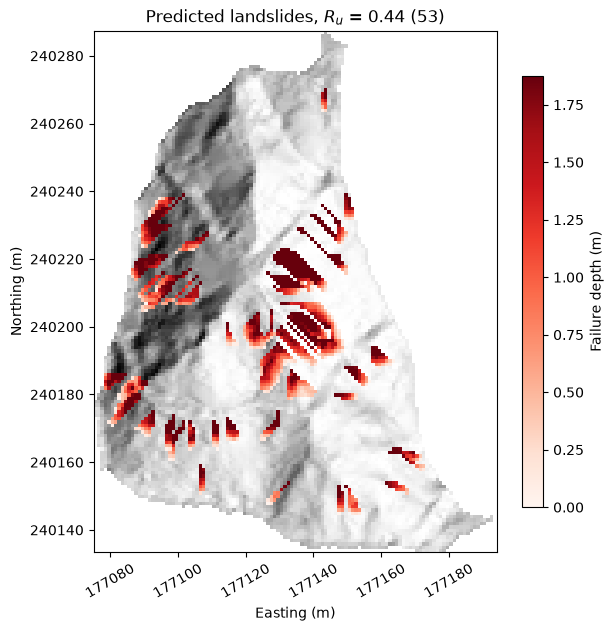

In [25]:
# failure depth of every landslide of the R_u run (a cell fails only once)
depth_ru = np.max(np.array(history_ru["failure__depth"]), axis=0).reshape(grid.shape)

# map of the landslides, colored by failure depth
fig, ax = plt.subplots(figsize=(6.5, 7))
map_axes(ax, f"Predicted landslides, $R_u$ = 0.44 ({int(state_ru['Total_Cumulative_NL_vector_with_time'][-1])})")
im = ax.imshow(np.ma.masked_where(depth_ru <= 0, depth_ru), origin="lower", extent=extent,
               cmap="Reds", vmin=0, vmax=Z_MAX, interpolation="nearest")
plt.colorbar(im, ax=ax, label="Failure depth (m)", shrink=0.8)

# same map limits as the other maps
ax.set_xlim(extent[0], extent[1])
ax.set_ylim(extent[2], extent[3])
plt.show()

### Frequency distributions and volume–area relation ($R_u$ = 0.44)

Same plots as for the first run: number of landslides in each size class (log-spaced), and volume against area with a power-law fit $V = \alpha\, A^{\gamma}$.

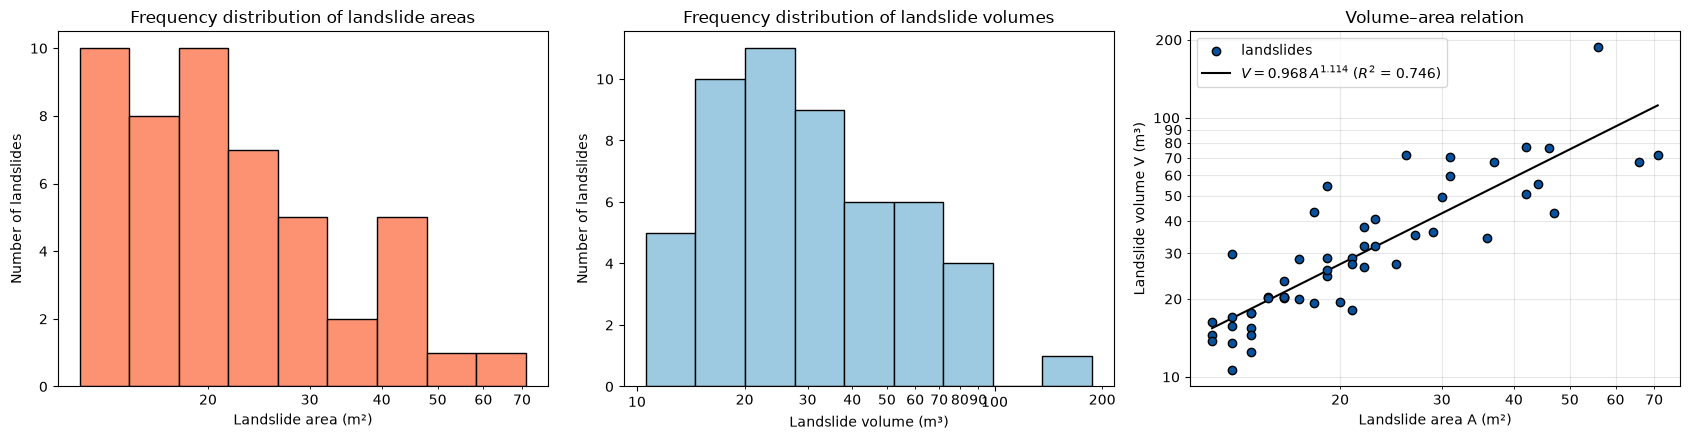

Number of landslides: 53
Area:   12 to 71 m²
Volume: 10.6 to 186.9 m³
Power-law fit: V = 0.9679 * A^1.1139   (R² = 0.746)


In [26]:
# area (m²) and volume (m³) of every landslide of the R_u run
areas_ru = np.asarray(state_ru["Individual_Cumulative_areas"], dtype=float)
volumes_ru = np.asarray(state_ru["Individual_Cumulative_volumes"], dtype=float)

# power-law fit of log10(V) against log10(A)
gamma_ru, log_alpha_ru = np.polyfit(np.log10(areas_ru), np.log10(volumes_ru), 1)
alpha_ru = 10**log_alpha_ru

# goodness of fit (R², in log space)
predicted_ru = log_alpha_ru + gamma_ru * np.log10(areas_ru)
r2_ru = 1 - np.sum((np.log10(volumes_ru) - predicted_ru)**2) / np.sum((np.log10(volumes_ru) - np.log10(volumes_ru).mean())**2)

# three plots side by side
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, values, color, label in ((ax1, areas_ru, "#fc9272", "Landslide area (m²)"),
                                 (ax2, volumes_ru, "#9ecae1", "Landslide volume (m³)")):

    # size classes, evenly spaced on a log scale
    bins = np.logspace(np.log10(values.min()), np.log10(values.max()), 10)

    # histogram: number of landslides in each class
    ax.hist(values, bins=bins, color=color, edgecolor="k")
    ax.set_xscale("log")

    # show plain numbers on the log axis
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.set_xlabel(label)
    ax.set_ylabel("Number of landslides")
    ax.set_title("Frequency distribution of " + label.split(" (")[0].lower() + "s")

# landslides as points, power-law fit as a line
ax3.scatter(areas_ru, volumes_ru, color="#08519c", edgecolor="k", zorder=3, label="landslides")
A_line = np.logspace(np.log10(areas_ru.min()), np.log10(areas_ru.max()), 50)
ax3.plot(A_line, alpha_ru * A_line**gamma_ru, color="k", lw=1.5,
         label=f"$V = {alpha_ru:.3f}\\,A^{{{gamma_ru:.3f}}}$ ($R^2$ = {r2_ru:.3f})")

# log-log axes with plain numbers, labels and legend
ax3.set_xscale("log")
ax3.set_yscale("log")
for axis in (ax3.xaxis, ax3.yaxis):
    axis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    axis.set_minor_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax3.set_xlabel("Landslide area A (m²)")
ax3.set_ylabel("Landslide volume V (m³)")
ax3.set_title("Volume–area relation")
ax3.grid(alpha=0.3, which="both")
ax3.legend()
plt.tight_layout()
plt.show()

# summary
print(f"Number of landslides: {len(areas_ru)}")
print(f"Area:   {areas_ru.min():.0f} to {areas_ru.max():.0f} m²")
print(f"Volume: {volumes_ru.min():.1f} to {volumes_ru.max():.1f} m³")
print(f"Power-law fit: V = {alpha_ru:.4f} * A^{gamma_ru:.4f}   (R² = {r2_ru:.3f})")